# Práctica 2 EDA — Rol E: Desbalance de clases

**Sección 6 de la práctica.** Este notebook:

1. **Diagnostica** el desbalance en Titanic y Credit Card Fraud (conteos, %, IR).
2. **Explica por qué el accuracy engaña** con un clasificador que siempre predice la clase mayoritaria.
3. **Compara 5 estrategias** con el mismo modelo (`modelo_base()` = `LogisticRegression(max_iter=1000)`, Rol A)
   y la misma evaluación (`evaluar()`, Rol A): sin balanceo, `class_weight='balanced'`, `RandomOverSampler`,
   `RandomUnderSampler` y `SMOTE`.
4. Elige la mejor estrategia por dataset y justifica su riesgo.

**Reglas comunes que respeta:** `RANDOM_STATE = 42`, split 70/30 estratificado (`dividir()` de `src/utils.py`),
preprocesamiento (`preprocesador_minimo()` de `src/utils.py`) **ajustado solo con train**, y **remuestreo solo
sobre train** (el test queda intacto).

### Uso de IA generativa
Se usó Claude para generar la estructura inicial del notebook.
El código fue revisado y ejecutado por el integrante del Rol E, quien puede explicar.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

sys.path.append("..")
from src.utils import (RANDOM_STATE, DATASETS, cargar_datos, dividir,
                       preprocesador_minimo, modelo_base, evaluar, guardar_resultados)

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figuras";     FIG.mkdir(exist_ok=True)
RES = ROOT / "resultados";  RES.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

### Preparación (preprocesamiento del Rol A, ajustado solo con train)
`preprocesador_minimo()` imputa (mediana/moda), escala numéricas y aplica one-hot — las mismas reglas que usa
`pipeline_base()` en el resto del equipo. Aquí se expone como arreglo numérico (en vez de ir dentro de un
`Pipeline`) porque el remuestreo (SMOTE, etc.) necesita datos ya numéricos **antes** de entrar al modelo.

In [2]:
def preparar(nombre):
    df = cargar_datos(nombre)
    X_train, X_test, y_train, y_test = dividir(df, nombre)
    prep = preprocesador_minimo(X_train).fit(X_train)       # ajustado SOLO con train
    return prep.transform(X_train), prep.transform(X_test), np.asarray(y_train), np.asarray(y_test)

## Parte 1 — Diagnóstico del desbalance

**IR (Imbalance Ratio)** = N_mayoritaria / N_minoritaria. Si IR > 1.5 el dataset se considera desbalanceado.

In [3]:
filas = []
for nombre, cfg in DATASETS.items():
    y = cargar_datos(nombre)[cfg["target"]]
    conteo = y.value_counts()
    filas.append({"dataset": nombre,
                  "n_total": len(y),
                  "n_clase_0": conteo.get(0, 0), "n_clase_1": conteo.get(1, 0),
                  "%_clase_0": 100 * conteo.get(0, 0) / len(y),
                  "%_clase_1": 100 * conteo.get(1, 0) / len(y),
                  "IR": conteo.max() / conteo.min(),
                  "desbalanceado (IR>1.5)": conteo.max() / conteo.min() > 1.5})
diagnostico = pd.DataFrame(filas).set_index("dataset")
diagnostico.to_csv(RES / "balanceo_diagnostico.csv")
diagnostico

,n_total,n_clase_0,n_clase_1,%_clase_0,%_clase_1,IR,desbalanceado (IR>1.5)
dataset,,,,,,,
titanic,891,549,342,61.6162,38.3838,1.6053,True
fraud,284807,284315,492,99.8273,0.1727,577.8760,True


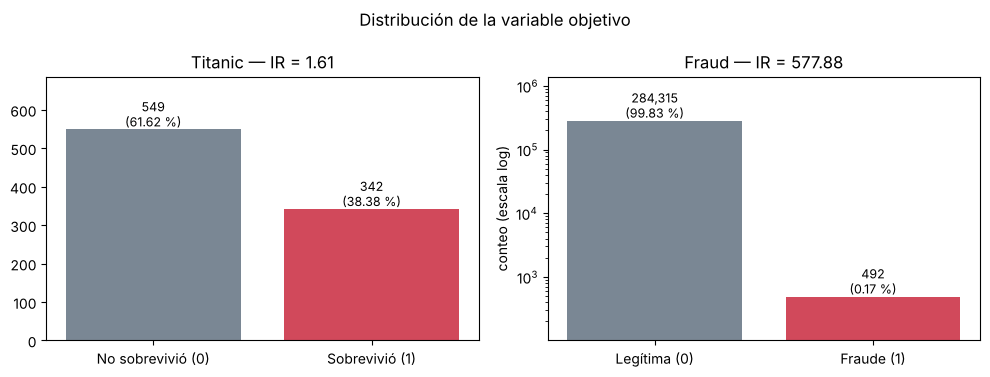

In [4]:
# Pregunta: ¿qué tan desigual es la proporción de clases en cada dataset?
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
etiquetas = {"titanic": ["No sobrevivió (0)", "Sobrevivió (1)"], "fraud": ["Legítima (0)", "Fraude (1)"]}
for ax, (nombre, fila) in zip(axes, diagnostico.iterrows()):
    vals = [fila["n_clase_0"], fila["n_clase_1"]]
    barras = ax.bar(etiquetas[nombre], vals, color=["#7a8794", "#d1495b"])
    for b, v, p in zip(barras, vals, [fila["%_clase_0"], fila["%_clase_1"]]):
        ax.annotate(f"{int(v):,}\n({p:.2f} %)", (b.get_x() + b.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{nombre.capitalize()} — IR = {fila['IR']:.2f}")
    ax.set_yscale("log" if nombre == "fraud" else "linear")
    ax.margins(y=0.25)
axes[1].set_ylabel("conteo (escala log)")
fig.suptitle("Distribución de la variable objetivo")
fig.tight_layout(); fig.savefig(FIG / "e_distribucion_clases.png", dpi=150); plt.show()

**Interpretación.** Titanic está *ligeramente* desbalanceado (IR ≈ 1.6, apenas arriba del umbral de 1.5).
Fraud tiene un desbalance **extremo** (IR ≈ 578): solo 0.17 % de las transacciones son fraude.
La gráfica de Fraud usa escala logarítmica; en escala lineal la barra de fraudes sería invisible.

### ¿Por qué el accuracy engaña?
Un "modelo" que **siempre** predice la clase mayoritaria no aprende nada, pero en Fraud obtiene un accuracy casi perfecto.

In [5]:
filas = []
for nombre in DATASETS:
    X_train, X_test, y_train, y_test = preparar(nombre)
    tonto = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    pred = tonto.predict(X_test)
    res = evaluar(tonto, X_train, y_train, X_test, y_test, nombre=f"Dummy ({nombre})", mostrar=False)
    filas.append({"dataset": nombre,
                  "accuracy": res["accuracy"],
                  "recall (clase 1)": res["recall"],
                  "F1 (clase 1)": res["f1"],
                  "positivos detectados": int(res["TP"]),
                  "positivos en test": int(y_test.sum())})
pd.DataFrame(filas).set_index("dataset")

,accuracy,recall (clase 1),F1 (clase 1),positivos detectados,positivos en test
dataset,,,,,
titanic,0.6157,0.0000,0.0000,0,103
fraud,0.9983,0.0000,0.0000,0,148


**Interpretación.** En Fraud, decir siempre "no fraude" da ~99.8 % de accuracy con **recall = 0**: no detecta ningún fraude.
El accuracy está dominado por la clase mayoritaria, así que en datos desbalanceados hay que mirar
**precision, recall, F1 y PR-AUC de la clase minoritaria**. En Titanic el mismo truco da ~62 %, lo que muestra
que el problema crece con el IR.

## Parte 2 — Estrategias de balanceo

Mismo modelo (`modelo_base()`), mismo split, misma `evaluar()`, todos del Rol A. El remuestreo se aplica
**solo a `X_train, y_train`**; `X_test, y_test` nunca se tocan.

In [6]:
ESTRATEGIAS = {
    "Sin balanceo":            (lambda: modelo_base(),                         None),
    "class_weight='balanced'": (lambda: modelo_base(class_weight="balanced"), None),
    "RandomOverSampler":       (lambda: modelo_base(), lambda: RandomOverSampler(random_state=RANDOM_STATE)),
    "RandomUnderSampler":      (lambda: modelo_base(), lambda: RandomUnderSampler(random_state=RANDOM_STATE)),
    "SMOTE":                   (lambda: modelo_base(), lambda: SMOTE(random_state=RANDOM_STATE)),
}

def correr_estrategias(nombre):
    X_train, X_test, y_train, y_test = preparar(nombre)
    y_test_original = y_test.copy()
    filas, matrices, probas, tamanos = [], {}, {}, []
    for est, (crear_modelo, crear_sampler) in ESTRATEGIAS.items():
        Xtr, ytr = X_train, y_train
        if crear_sampler is not None:
            Xtr, ytr = crear_sampler().fit_resample(X_train, y_train)    # SOLO train
        modelo = crear_modelo()
        res = evaluar(modelo, Xtr, ytr, X_test, y_test, nombre=f"{nombre}/{est}", mostrar=False)
        proba = modelo.predict_proba(X_test)[:, 1]
        filas.append({"estrategia": est, **{k: res[k] for k in
                      ("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "TN", "FP", "FN", "TP")}})
        matrices[est] = confusion_matrix(y_test, modelo.predict(X_test))
        probas[est] = proba
        tamanos.append({"estrategia": est, "n_train": len(ytr),
                        "clase_0": int((ytr == 0).sum()), "clase_1": int((ytr == 1).sum())})
    assert np.array_equal(y_test, y_test_original), "¡El test se modificó!"
    tabla = pd.DataFrame(filas).set_index("estrategia")
    tabla.to_csv(RES / f"balanceo_{nombre}.csv")
    return tabla, matrices, probas, y_test, pd.DataFrame(tamanos).set_index("estrategia")

resultados = {n: correr_estrategias(n) for n in DATASETS}

### Titanic — tabla comparativa

In [7]:
resultados["titanic"][0]

,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP
estrategia,,,,,,,,,,
Sin balanceo,0.7985,0.7475,0.7184,0.7327,0.8495,0.8036,140,25,29,74
class_weight='balanced',0.8022,0.7155,0.8058,0.7580,0.8491,0.8027,132,33,20,83
RandomOverSampler,0.7948,0.7034,0.8058,0.7511,0.8475,0.8009,130,35,20,83
RandomUnderSampler,0.8060,0.7257,0.7961,0.7593,0.8516,0.7974,134,31,21,82
SMOTE,0.8060,0.7217,0.8058,0.7615,0.8509,0.8016,133,32,20,83


### Credit Card Fraud — tabla comparativa

In [8]:
resultados["fraud"][0]

,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP
estrategia,,,,,,,,,,
Sin balanceo,0.9991,0.8505,0.6149,0.7137,0.9567,0.7080,85279,16,57,91
class_weight='balanced',0.9786,0.0671,0.8784,0.1247,0.9681,0.7050,83488,1807,18,130
RandomOverSampler,0.9785,0.0668,0.8784,0.1241,0.9682,0.7051,83478,1817,18,130
RandomUnderSampler,0.9774,0.0641,0.8851,0.1195,0.9714,0.5857,83381,1914,17,131
SMOTE,0.9777,0.0645,0.8784,0.1202,0.9672,0.7062,83410,1885,18,130


### Tamaño de train después de remuestrear (comprobación de la regla de oro)
El test conserva su distribución original en todas las estrategias (lo verifica el `assert` de arriba).

In [9]:
for nombre in DATASETS:
    print(f"\n{nombre.upper()}  —  test: {len(resultados[nombre][3])} filas, "
          f"{int(resultados[nombre][3].sum())} positivos (sin cambios)")
    display(resultados[nombre][4])


TITANIC  —  test: 268 filas, 103 positivos (sin cambios)


,n_train,clase_0,clase_1
estrategia,,,
Sin balanceo,623,384,239
class_weight='balanced',623,384,239
RandomOverSampler,768,384,384
RandomUnderSampler,478,239,239
SMOTE,768,384,384



FRAUD  —  test: 85443 filas, 148 positivos (sin cambios)


,n_train,clase_0,clase_1
estrategia,,,
Sin balanceo,199364,199020,344
class_weight='balanced',199364,199020,344
RandomOverSampler,398040,199020,199020
RandomUnderSampler,688,344,344
SMOTE,398040,199020,199020


### Matrices de confusión
Pregunta: ¿cuántos positivos detecta cada estrategia y cuántas falsas alarmas genera?

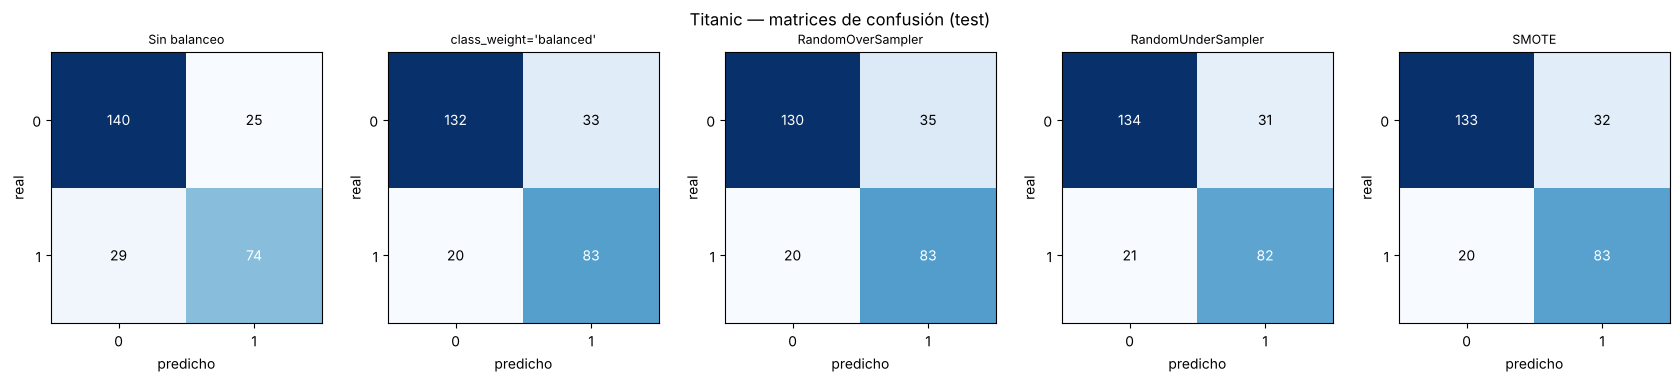

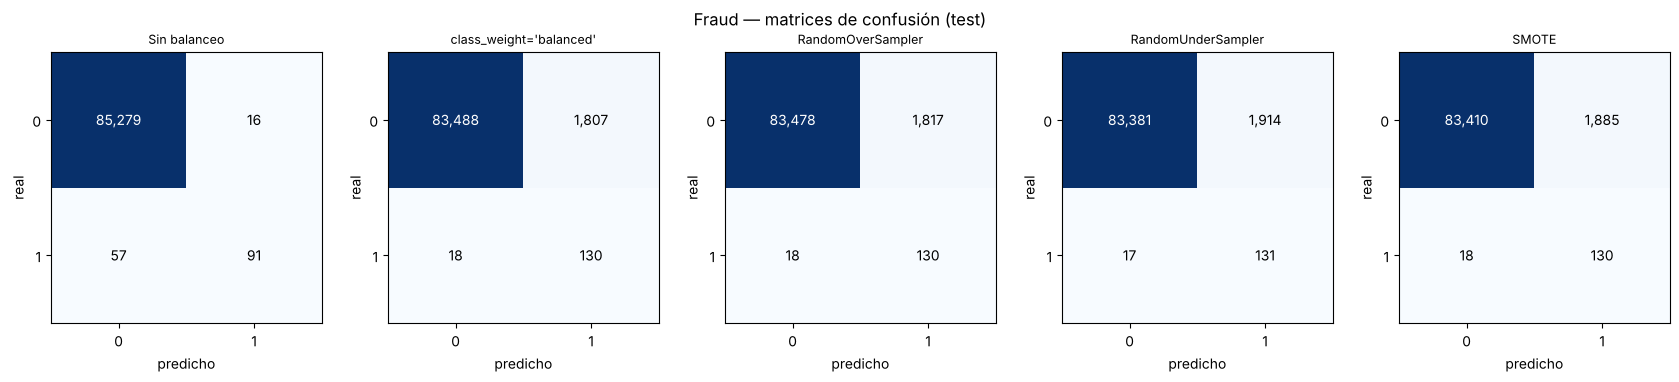

In [10]:
for nombre in DATASETS:
    _, matrices, _, _, _ = resultados[nombre]
    fig, axes = plt.subplots(1, len(matrices), figsize=(17, 3.6))
    for ax, (est, cm) in zip(axes, matrices.items()):
        ax.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f"{v:,}", ha="center", va="center",
                    color="white" if v > cm.max() / 2 else "black", fontsize=10)
        ax.set_title(est, fontsize=9); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xlabel("predicho"); ax.set_ylabel("real")
    fig.suptitle(f"{nombre.capitalize()} — matrices de confusión (test)")
    fig.tight_layout(); fig.savefig(FIG / f"e_matrices_{nombre}.png", dpi=150); plt.show()

### Precision vs. recall por estrategia
Pregunta: ¿qué se gana y qué se pierde al balancear? (gráfica para la presentación del Rol C)

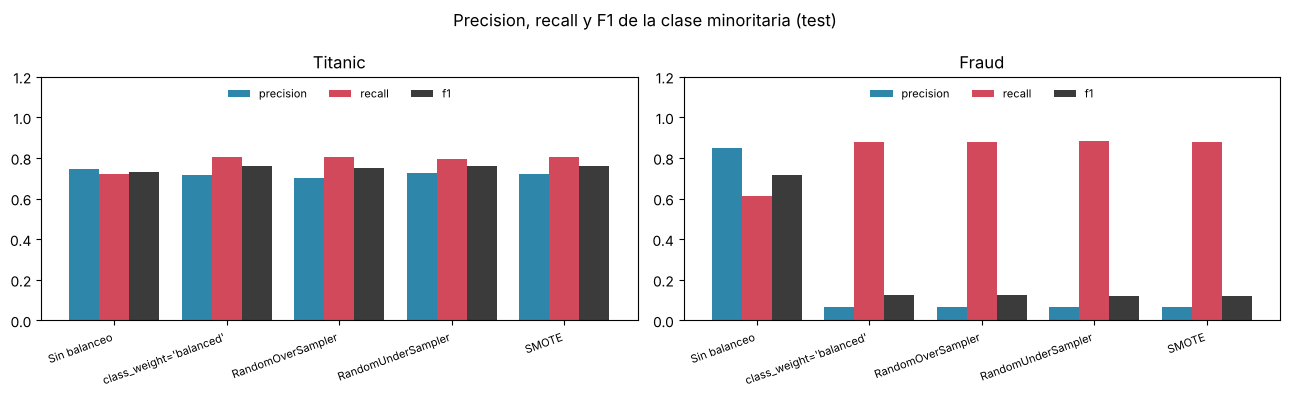

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, nombre in zip(axes, DATASETS):
    t = resultados[nombre][0][["precision", "recall", "f1"]]
    t.plot.bar(ax=ax, color=["#2e86ab", "#d1495b", "#3b3b3b"], width=0.8, rot=20)
    ax.set_ylim(0, 1.2); ax.set_title(nombre.capitalize()); ax.set_xlabel("")
    ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right"); lbl.set_fontsize(8)
fig.suptitle("Precision, recall y F1 de la clase minoritaria (test)")
fig.tight_layout(); fig.savefig(FIG / "e_metricas_estrategias.png", dpi=150); plt.show()

### Curvas Precision-Recall (Fraud)
Pregunta: ¿el balanceo mejora la capacidad del modelo para **ordenar** fraudes por riesgo, o solo mueve el umbral?

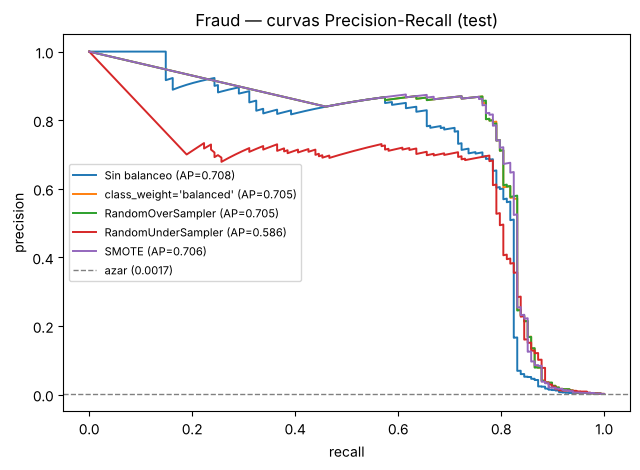

In [12]:
_, _, probas, y_test, _ = resultados["fraud"]
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for est, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=f"{est} (AP={average_precision_score(y_test, p):.3f})", lw=1.4)
ax.axhline(y_test.mean(), ls="--", c="gray", lw=1, label=f"azar ({y_test.mean():.4f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Fraud — curvas Precision-Recall (test)")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / "e_curvas_pr_fraud.png", dpi=150); plt.show()

## Análisis y elección de estrategia

> Cifras generadas con `src/utils.py` del Rol A (imputación mediana/moda + one-hot + escalado). En Fraud se mantiene la columna `Time`, tal como la dejó configurada A en `DATASETS["fraud"]["excluir"]`.

### Titanic (IR ≈ 1.6, desbalance leve)
- Todas las estrategias de balanceo suben el **recall** de 0.72 a ~0.80–0.81 (detectan ~9 sobrevivientes más de 103)
  a cambio de una caída pequeña de **precision** (0.75 → ~0.70–0.73). El F1 pasa de 0.733 a 0.751–0.761.
- El **ROC-AUC casi no cambia** (0.848–0.852): el modelo ordena igual; el balanceo solo mueve el punto de corte.
- Las diferencias entre las 4 técnicas son de 1–3 pasajeros en un test de 268, así que **no son significativas**.

**Elección: `class_weight='balanced'`.** Da prácticamente el mismo F1 que SMOTE (0.758 vs 0.761, un pasajero de diferencia)
sin crear casos artificiales ni descartar datos, y no cambia el tamaño de train.
*Riesgo:* ligero aumento de falsos positivos (25 → 33); con un desbalance tan leve, el beneficio también es modesto.

### Credit Card Fraud (IR ≈ 578, desbalance extremo)
- **Sin balanceo:** precision 0.85 y recall 0.61. Detecta 91 de 148 fraudes con solo 16 falsas alarmas. Es el mejor F1 (0.714).
- **Con balanceo** (class_weight, ROS, SMOTE): el recall sube a 0.88 (130–131 fraudes detectados, ~40 más),
  pero la precision se desploma a ~0.065: **~1,800–1,900 falsas alarmas**, unas 14 por cada fraude detectado. El F1 cae a ~0.12.
- **PR-AUC prácticamente igual** (0.705–0.708) en sin balanceo, class_weight, ROS y SMOTE: estas técnicas **no hacen al modelo
  mejor discriminando**, solo lo vuelven más "agresivo" (desplazan el umbral de decisión).
- **RandomUnderSampler** es la peor en PR-AUC (0.59): deja solo 688 filas de train de ~199 mil, **pierde información**.

**Elección: `class_weight='balanced'`**, por ser la que logra el recall alto (0.88) con el PR-AUC de las mejores, sin
duplicar filas (ROS), sin inventar transacciones (SMOTE) y sin tirar datos (RUS). En fraude, dejar pasar un fraude suele
costar más que revisar una alarma, por eso se prioriza el recall.
*Riesgo:* precision muy baja (~7 %). Para usarlo en la práctica habría que **ajustar el umbral** de decisión con una
partición de validación sacada de train (nunca con test); si el costo de revisar alarmas es alto, "sin balanceo" es
la opción más equilibrada por F1.

### Riesgos de cada técnica (para la defensa)
| Técnica | Riesgo principal |
|---|---|
| `class_weight` | Más falsos positivos; no crea ni borra datos |
| RandomOverSampler | Sobreajuste: repite exactamente los mismos positivos |
| RandomUnderSampler | Pérdida de información: descarta casi toda la clase mayoritaria |
| SMOTE | Casos artificiales que pueden no ser realistas o caer en zonas de la otra clase |

### ¿Por qué el remuestreo solo se aplica a train?
Si se remuestrea antes del split, copias (ROS) o interpolaciones (SMOTE) de un mismo caso quedan en train y en test:
el modelo "ya vio" el test y las métricas salen infladas. Además, el test debe conservar la proporción real de clases
para medir cómo funcionaría el modelo con datos nuevos.

## Pendiente al integrar
1. `DATASETS["fraud"]["excluir"]` no quita `Time`; si el Rol B/D deciden que hay fuga de información,
   avisar para ajustar `src/utils.py` y volver a correr este notebook.
2. Confirmar que `imbalanced-learn` ya está en `requirements.txt` (ya está).
3. Mandar a C `figuras/e_metricas_estrategias.png` y `resultados/balanceo_fraud.csv`.